In [60]:
import pandas as pd

In [61]:
df = pd.read_csv(r"d:\thony\used_cars_prediction\data\vehicles.csv")

In [62]:
features = [
    'year',
    'manufacturer',
    'odometer',
    'fuel',
    'transmission',
    'title_status',
    'type',
    'state'
]

target = 'price'

df_ml = df[features + [target]].copy()

print(df_ml.shape)
print(df_ml.isnull().sum())

(426880, 9)
year             1205
manufacturer    17646
odometer         4400
fuel             3013
transmission     2556
title_status     8242
type            92858
state               0
price               0
dtype: int64


In [63]:
df_ml[df_ml['price'] < 0]


,year,manufacturer,odometer,fuel,transmission,title_status,type,state,price


In [64]:
important_columns = [
    'year',
    'manufacturer',
    'odometer',
    'price'
]

df_ml = df_ml.dropna(subset=important_columns)

In [65]:
print(df_ml.shape)
print(df_ml.isnull().sum())

(405077, 9)
year                0
manufacturer        0
odometer            0
fuel             2009
transmission     1624
title_status     7204
type            85533
state               0
price               0
dtype: int64


In [66]:
df_ml = df_ml[df_ml['price'] <= 57050]
df_ml = df_ml[df_ml['price'] > 500]

In [67]:
columns_to_fill = [
    'fuel',
    'transmission',
    'title_status',
    'type'
]

df_ml[columns_to_fill] = df_ml[columns_to_fill].fillna('unknown')

In [68]:
df_ml.dtypes

year            float64
manufacturer        str
odometer        float64
fuel                str
transmission        str
title_status        str
type                str
state               str
price             int64
dtype: object

In [69]:
import numpy as np

df_ml['price'] = np.log1p(df_ml['price'])
df_ml['odometer'] = np.log1p(df_ml['odometer'])

In [70]:
df_encoded = pd.get_dummies(df_ml, columns=['manufacturer', 'fuel', 'transmission', 'title_status', 'type', 'state'])
df_encoded.head()

,year,odometer,price,manufacturer_acura,manufacturer_alfa-romeo,manufacturer_aston-martin,manufacturer_audi,manufacturer_bmw,manufacturer_buick,manufacturer_cadillac,...,state_sd,state_tn,state_tx,state_ut,state_va,state_vt,state_wa,state_wi,state_wv,state_wy
27,2014.0,10.966887,10.422013,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
28,2010.0,11.173669,10.025307,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29,2020.0,9.860632,10.586357,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
30,2017.0,10.624371,10.341452,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
31,2013.0,11.759793,9.615872,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


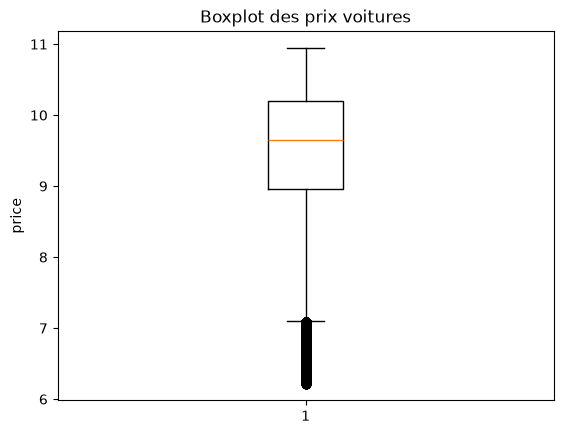

In [71]:
import matplotlib.pyplot as plt

plt.boxplot(df_encoded["price"])

plt.ylabel("price")
plt.title("Boxplot des prix voitures")

plt.show()

In [72]:
df_encoded.to_csv('data/vehicles_encoded.csv', index=False)
